In [6]:
# %% Paso 1: Importación de paquetes ============================

# Rutas relativas
from pathlib import Path

# Manipulación de datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pruebas estadísticas y gráficos Q-Q de Scipy
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels (FAC/FACP, pruebas de diagnóstico y SARIMAX)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss


# %% Configuración de ruta relativa ============================

BASE_DIR = Path('.').resolve()
DATA_DIR = BASE_DIR / "datos"

print("Directorio raíz del proyecto:", BASE_DIR)
print("Carpeta de datos lista en:", DATA_DIR)


Directorio raíz del proyecto: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II
Carpeta de datos lista en: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II\datos


In [7]:
# Carga de la serie con ruta relativa
ruta_csv = DATA_DIR / "serie_economica.csv"

# Leer CSV parseando la columna de fechas de la FRED
df = pd.read_csv(ruta_csv, parse_dates=['observation_date'], index_col='observation_date')
df.columns = ['precio_gasolina']

# Convertir valores a numérico y eliminar nulos si existieran
df['precio_gasolina'] = pd.to_numeric(df['precio_gasolina'], errors='coerce')
df = df.dropna()

# Mostrar el total de observaciones
print(f"Número total de observaciones (T): {len(df)}")

# Visualizar las primeras filas del DataFrame
df.head()


Número total de observaciones (T): 1882


,precio_gasolina
observation_date,
1990-08-20,1.191
1990-08-27,1.245
1990-09-03,1.242
1990-09-10,1.252
1990-09-17,1.266


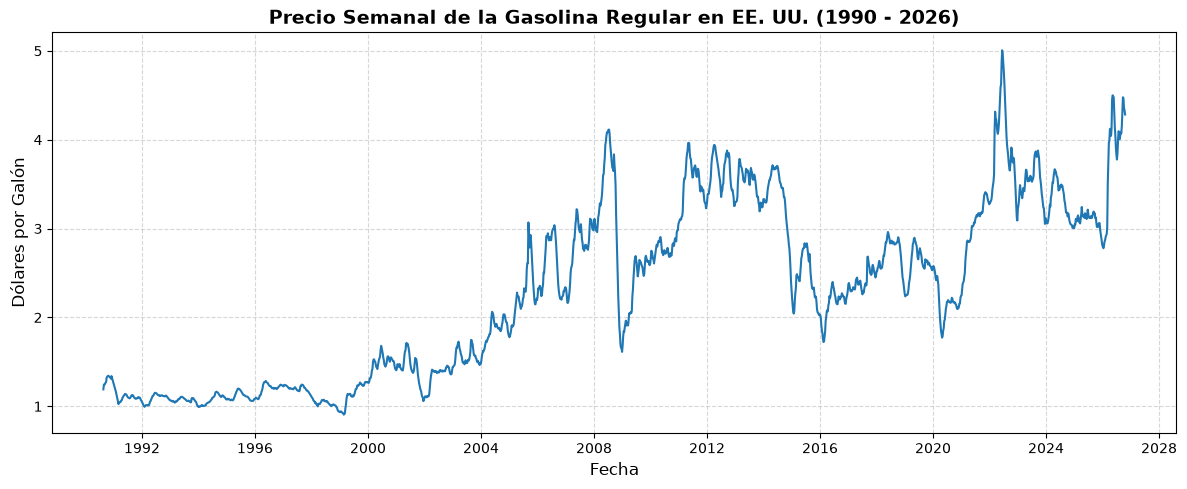

In [9]:
# %% =======================================================
# PASO 1: IDENTIFICACIÓN
# ==========================================================
# Graficar la serie de tiempo en niveles
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['precio_gasolina'], color='#1f77b4', linewidth=1.5)
plt.title('Precio Semanal de la Gasolina Regular en EE. UU. (1990 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Dólares por Galón', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()




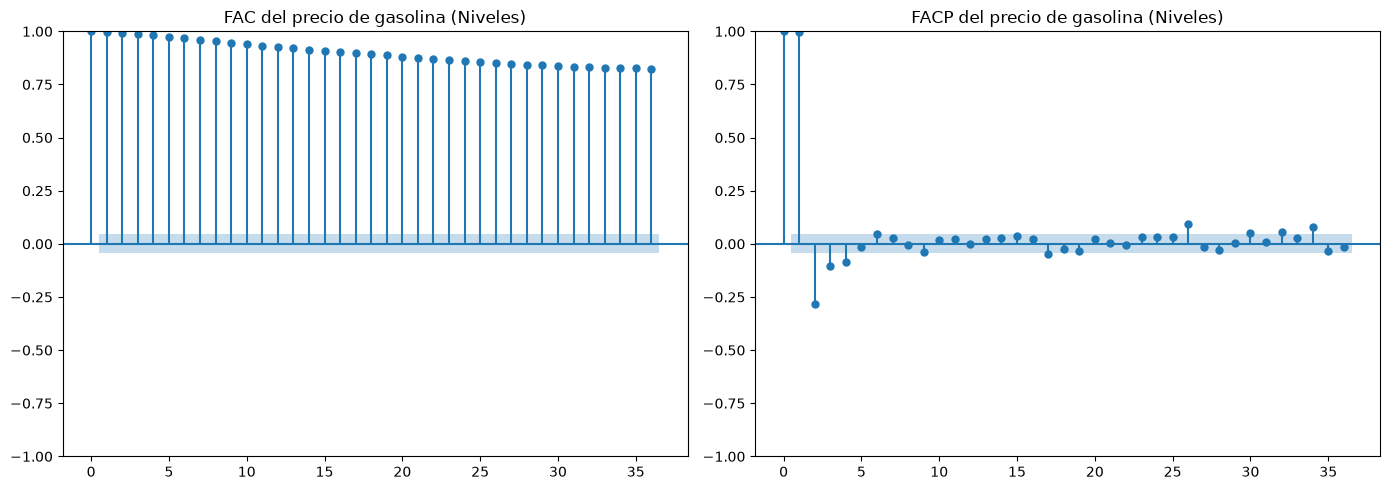

In [10]:
## %% FAC y FACP de la serie original =========================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)
axes[0].set_title("FAC del precio de gasolina (Niveles)")

plot_pacf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title("FACP del precio de gasolina (Niveles)")

plt.tight_layout()
plt.show()

In [11]:
# %% Tests de Raíz Unitaria (ADF y KPSS) =========================

# Test Augmented Dickey-Fuller (ADF)
adf_result = adfuller(df['precio_gasolina'])

print("=== Test ADF (Serie en Niveles) ===")
print("Estadístico ADF:", adf_result[0])
print("p-valor:", adf_result[1])
print("Rezagos usados:", adf_result[2])
for nivel, valor in adf_result[4].items():
    print(f"  Crítico {nivel}: {valor}")

if adf_result[1] < 0.05:
    print("ADF: Rechazamos H0 -> La serie es ESTACIONARIA.")
else:
    print("ADF: No rechazamos H0 -> La serie NO es estacionaria.")

# Test KPSS
kpss_result = kpss(df['precio_gasolina'], regression="c", nlags="auto")

print("\n=== Test KPSS (Serie en Niveles) ===")
print("Estadístico KPSS:", kpss_result[0])
print("p-valor:", kpss_result[1])
for nivel, valor in kpss_result[3].items():
    print(f"  Crítico {nivel}: {valor}")

if kpss_result[1] < 0.05:
    print("KPSS: Rechazamos H0 -> La serie NO es estacionaria.")
else:
    print("KPSS: No rechazamos H0 -> La serie es ESTACIONARIA.")
    

=== Test ADF (Serie en Niveles) ===
Estadístico ADF: -1.9352240027244718
p-valor: 0.31567630515245365
Rezagos usados: 9
  Crítico 1%: -3.4338480179204556
  Crítico 5%: -2.863085177979608
  Crítico 10%: -2.567592596439203
ADF: No rechazamos H0 -> La serie NO es estacionaria.

=== Test KPSS (Serie en Niveles) ===
Estadístico KPSS: 4.991310469082142
p-valor: 0.01
  Crítico 10%: 0.347
  Crítico 5%: 0.463
  Crítico 2.5%: 0.574
  Crítico 1%: 0.739
KPSS: Rechazamos H0 -> La serie NO es estacionaria.


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_23336\796249481.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(df['precio_gasolina'], regression="c", nlags="auto")


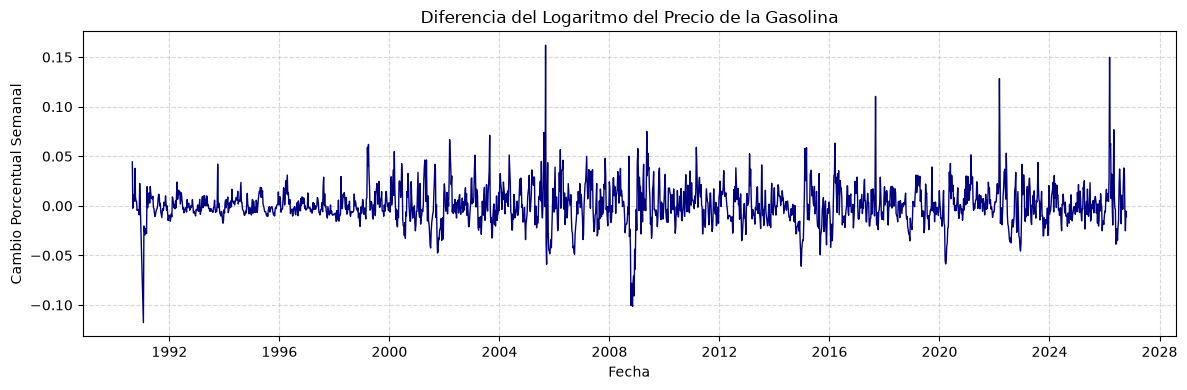

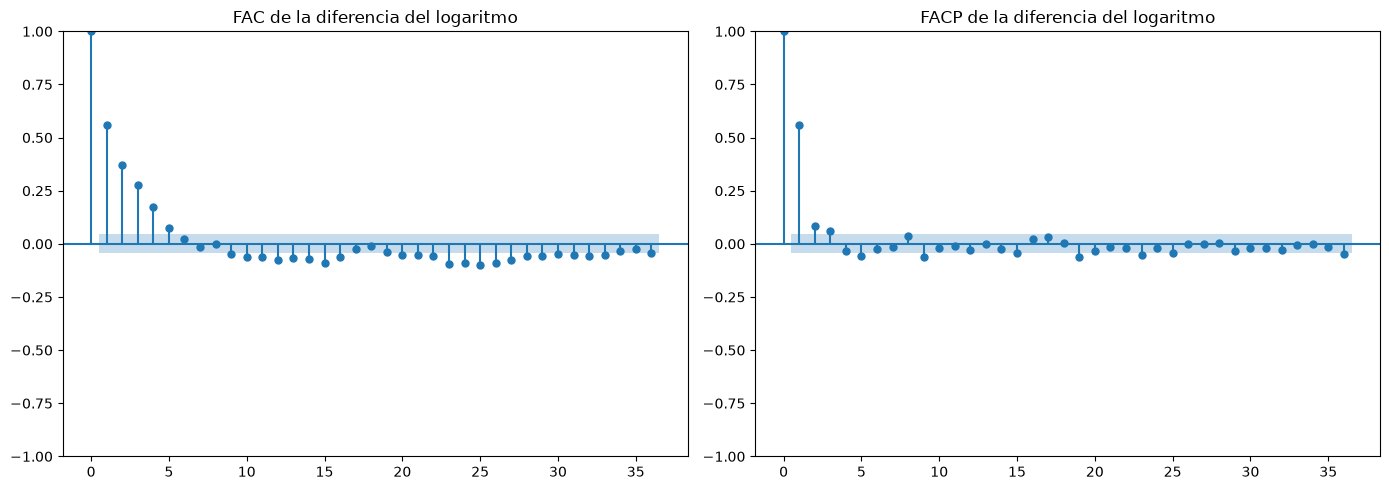

In [12]:
# Nota: Según los resultados de la prueba ADF y KPSS, hay que 
#       diferenciar la serie. Es una buena noticia que ambos resultados coincidieran.
# %% Serie transformada: Diferencia del Logaritmo =========================

# Crear las transformaciones en el DataFrame
df['log_gasolina'] = np.log(df['precio_gasolina'])
df['log_diff'] = df['log_gasolina'].diff()

# Serie limpia para análisis
serie_estacionaria = df['log_diff'].dropna()

# Gráfico de la serie diferenciada
plt.figure(figsize=(12, 4))
plt.plot(serie_estacionaria, color='navy', linewidth=1)
plt.title("Diferencia del Logaritmo del Precio de la Gasolina")
plt.xlabel("Fecha")
plt.ylabel("Cambio Porcentual Semanal")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# FAC y FACP de la serie transformada para proponer ordenes p y q
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    serie_estacionaria,
    lags=36,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)
axes[0].set_title("FAC de la diferencia del logaritmo")

plot_pacf(
    serie_estacionaria,
    lags=36,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title("FACP de la diferencia del logaritmo")

plt.tight_layout()
plt.show()



In [13]:
# %% Identificación del modelo usando FAC y FACP

# La FAC muestra un decaimiento progresivo (suave / geométrico).
# La FACP presenta un corte abrupto en el primer rezago.
# Por tanto, se propone inicialmente un modelo AR(1) sobre la serie
# transformada, equivalente a un ARIMA(1, 1, 0) sobre log(precio_gasolina).

# P.d. También se puede considerar un modelo alternativo ARIMA(2, 1, 0)
#      dado el segundo rezago de la FACP, y comparar mediante los
#      criterios de información (AIC y BIC) en la etapa de estimación.
